In [2]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.multiclass import OneVsRestClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV, StratifiedKFold
import pandas as pd
from langdetect import detect, DetectorFactory
import matplotlib.pyplot as plt
import unicodedata
from sentence_transformers import SentenceTransformer
from sklearn.base import BaseEstimator, TransformerMixin
import nltk
from nltk.corpus import stopwords
from nltk.stem import SnowballStemmer
import string
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics import roc_auc_score, f1_score, classification_report, confusion_matrix
import numpy as np
from sklearn.metrics import roc_curve, auc, precision_recall_curve
from sklearn.preprocessing import label_binarize


C:\Users\lucas\OneDrive\Escritorio\TP 1 tweets\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
df = pd.read_csv("./ia_tweets.csv")

df.head()

,ID,text,polarity,favorite_count,retweet_count,user_followers_count,user_friends_count,user_favourites_count,user_statuses_count,user_verified,user_has_extended_profile,user_is_translator,user_protected,user_default_profile
0,0,Comentaba en una charla sobre IA que el proble...,N,21,7,15936,2395,66945,68578,0,1,0,0,0
1,1,"@alvaropons Eso es imposible. Y sí, va a gener...",N,1,0,685,851,169490,128555,0,1,0,0,1
2,2,@alvaropons Lo disruptivo es que tras años de ...,NEU,1,0,685,851,169490,128555,0,1,0,0,1
3,3,"@alvaropons ¿""Prohibición del uso comercial de...",N,0,0,4877,538,6123,3156,0,1,0,0,0
4,4,@santoroydonoso Cómo se está estudiando prohib...,NEU,0,0,15936,2395,66945,68578,0,1,0,0,0


In [4]:
df.dtypes

ID                           int64
text                           str
polarity                       str
favorite_count               int64
retweet_count                int64
user_followers_count         int64
user_friends_count           int64
user_favourites_count        int64
user_statuses_count          int64
user_verified                int64
user_has_extended_profile    int64
user_is_translator           int64
user_protected               int64
user_default_profile         int64
dtype: object

In [5]:
DetectorFactory.seed = 0

df['idioma'] = df['text'].apply(detect)

df = df[df["idioma"] == "es"]

df = df.drop(columns=["ID","user_has_extended_profile", "user_is_translator", "user_protected", "idioma"])

In [6]:
def filtrar_por_polaridad(field):
    return df[df["polarity"] == field]

cant_negativos = len(filtrar_por_polaridad("N"))
cant_neutros = len(filtrar_por_polaridad("NEU"))
cant_positivos =  len(filtrar_por_polaridad("P"))

print('Cantidad de tweets: ', len(df))
print('Tweets Negativos: ', cant_negativos, ', Neutros' , cant_neutros,', Positivos', cant_positivos)

# Cantidad de datos desbalanceada, se tiene mucho mas datos neutros que negativos o positivos.

Cantidad de tweets:  3660
Tweets Negativos:  551 , Neutros 2417 , Positivos 692


In [7]:
cantidad_na = df.isna().sum()
print(cantidad_na)

#(cantidad_negativos_columna("favorite_count"))

# No hay nulls o valores

text                     0
polarity                 0
favorite_count           0
retweet_count            0
user_followers_count     0
user_friends_count       0
user_favourites_count    0
user_statuses_count      0
user_verified            0
user_default_profile     0
dtype: int64


In [8]:
cantidad_negativos = (df.select_dtypes(include='number') < 0).sum()
print(cantidad_negativos)

favorite_count           0
retweet_count            0
user_followers_count     0
user_friends_count       0
user_favourites_count    0
user_statuses_count      0
user_verified            0
user_default_profile     0
dtype: int64


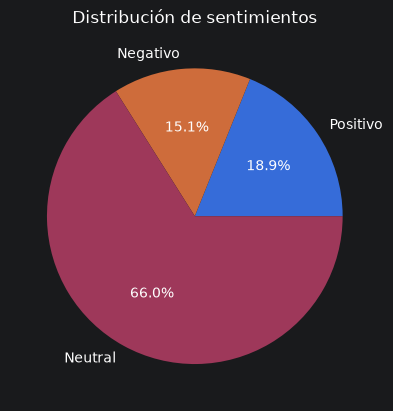

In [9]:
# Datos
clases = ['Positivo', 'Negativo', 'Neutral']
cantidades = [cant_positivos, cant_negativos, cant_neutros]

# Crear gráfico
plt.pie(cantidades, labels=clases, autopct='%1.1f%%')
plt.title('Distribución de sentimientos')
plt.show()

4.1519125683060105
2243
0


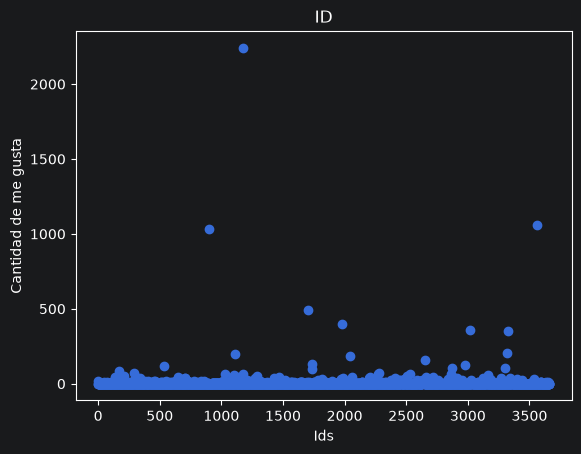

In [10]:
print(df["favorite_count"].mean())
print(df["favorite_count"].max())
print(df["favorite_count"].min())

plt.scatter(range(0,len(df)), df['favorite_count'])

plt.xlabel('Ids')
plt.ylabel('Cantidad de me gusta')
plt.title('ID')

plt.show()

0.9606557377049181
502
0


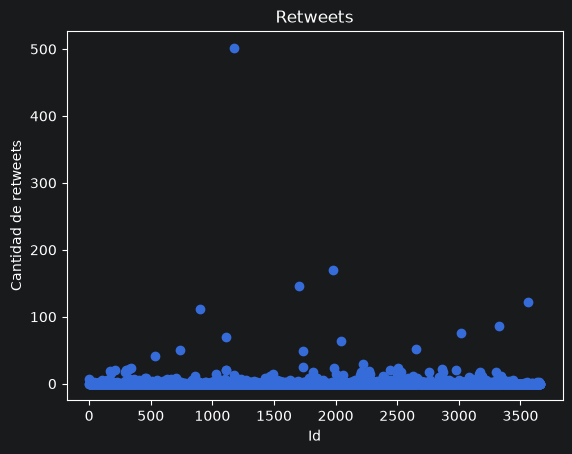

In [11]:
print(df["retweet_count"].mean())
print(df["retweet_count"].max())
print(df["retweet_count"].min())

plt.scatter(range(0,len(df)), df['retweet_count'])

plt.xlabel('Id')
plt.ylabel('Cantidad de retweets')
plt.title('Retweets')

plt.show()

Cantidad de tweets positivo con interaccion:  172
Cantidad de tweets negativos con interaccion:  139
Media de interacciones en positivos:  6.726878612716763
Media de interacciones en negativos:  3.8747731397459164


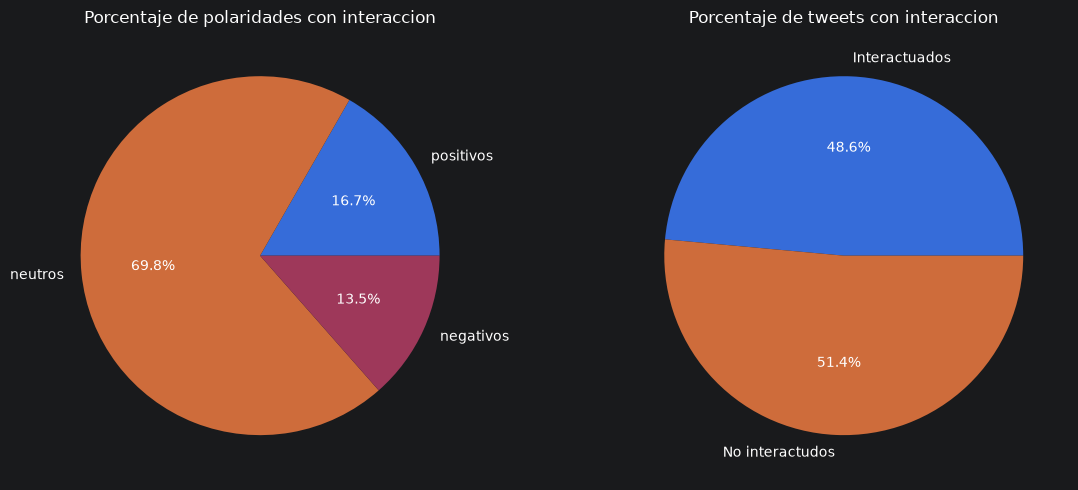

In [12]:
df['tweet_interactions'] = df['favorite_count'] + df['retweet_count']

tweets_con_interaccion = (df['tweet_interactions'] > 0).sum()
tweets_sin_interaccion = (df['tweet_interactions'] == 0).sum()

positivos_con_interaccion = (df[df['polarity'] == 'P']['tweet_interactions'] > 1).sum()
neutros_con_interaccion = (df[df['polarity'] == 'NEU']['tweet_interactions'] > 1).sum()
negativos_con_interaccion = (df[df['polarity'] == 'N']['tweet_interactions'] > 1).sum()
interaccion_positivos_media = df[df['polarity'] == 'P']['tweet_interactions'].mean()
interaccion_negativos_media = df[df['polarity'] == 'N']['tweet_interactions'].mean()

print("Cantidad de tweets positivo con interaccion: ", positivos_con_interaccion)
print("Cantidad de tweets negativos con interaccion: ", negativos_con_interaccion)
print("Media de interacciones en positivos: ", interaccion_positivos_media)
print("Media de interacciones en negativos: ", interaccion_negativos_media)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].pie([positivos_con_interaccion, neutros_con_interaccion, negativos_con_interaccion], labels=["positivos", "neutros", "negativos"], autopct='%1.1f%%')
ax[0].set_title('Porcentaje de polaridades con interaccion')

ax[1].pie([tweets_con_interaccion, tweets_sin_interaccion],
  labels=["Interactuados", "No interactudos"], autopct='%1.1f%%')
ax[1].set_title('Porcentaje de tweets con interaccion')

plt.tight_layout()
plt.show()

In [13]:
 #text
#polarity
#favorite_count
#retweet_count
#user_followers_count
#user_friends_count
#user_favourites_count         TEST (Likes que dio)
#user_statuses_count           TEST (Publicaciones y comentarios suyos)
#user_verified                 TEST
#user_default_profile          TEST (Pagina de perfil default)

def contar_emojis(texto):
    return sum(1 for caracter in str(texto) if unicodedata.category(caracter) == 'So')

df["hashtag_count"] = df['text'].apply(lambda texto: texto.count('#'))
df["mention_count"] = df['text'].apply(lambda texto: texto.count('@'))
df["url_count"] = df['text'].apply(lambda texto: texto.count('http'))
df["interrogation_count"] = df['text'].apply(lambda texto: texto.count('?') )
df["exclamation_count"] = df['text'].apply(lambda texto: texto.count('!'))



In [14]:
df["text"] = df["text"].str.replace(r"http\S+|www\.\S+", "URL", regex=True)
df["text"] = df["text"].str.replace(r"@\w+", "MENCION", regex=True)

df.head()

,text,polarity,favorite_count,retweet_count,user_followers_count,user_friends_count,user_favourites_count,user_statuses_count,user_verified,user_default_profile,tweet_interactions,hashtag_count,mention_count,url_count,interrogation_count,exclamation_count
0,Comentaba en una charla sobre IA que el proble...,N,21,7,15936,2395,66945,68578,0,0,28,0,0,1,0,0
1,"MENCION Eso es imposible. Y sí, va a generar u...",N,1,0,685,851,169490,128555,0,1,1,0,1,0,0,0
2,MENCION Lo disruptivo es que tras años de deci...,NEU,1,0,685,851,169490,128555,0,1,1,0,1,0,0,0
3,"MENCION ¿""Prohibición del uso comercial de las...",N,0,0,4877,538,6123,3156,0,0,0,0,1,0,1,0
4,MENCION Cómo se está estudiando prohibir chatG...,NEU,0,0,15936,2395,66945,68578,0,0,0,0,1,0,1,0


In [15]:
import emoji
from emosent import get_emoji_sentiment_rank

def emoji_features(text):
    scores = []
    for e in emoji.emoji_list(str(text)):
        try:
            rank = get_emoji_sentiment_rank(e["emoji"])
        except KeyError:
            rank = None
        if rank is not None:
            scores.append(rank["sentiment_score"])
    if not scores:
        return 0.0, 0, 0
    return (
        sum(scores) / len(scores),
        sum(s > 0.1 for s in scores),
        sum(s < -0.1 for s in scores),
    )

df[["emoji_score", "emoji_pos", "emoji_neg"]] = df["text"].apply(
    lambda t: pd.Series(emoji_features(t))
)

In [16]:
from sklearn.model_selection import train_test_split

print(df.shape)

X = df.drop(columns=["polarity"])
y = df["polarity"]

# 60% para train y 40% para test y validacion
X_train, X_test_val, y_train, y_test_val = train_test_split(
    X, y,
    test_size=0.40,
    random_state=42,
    stratify=y
)

# Segunda división: separar test y validación
X_test, X_val, y_test, y_val = train_test_split(
    X_test_val, y_test_val,
    test_size=0.5,
    random_state=42,
    stratify=y_test_val
)

print(len(X_train)/len(df))

(3660, 19)
0.6


In [17]:
from sklearn.preprocessing import StandardScaler

number_columns = ["favorite_count","retweet_count","user_followers_count", "user_friends_count", "user_favourites_count", "user_statuses_count", "tweet_interactions", "hashtag_count", "mention_count", "url_count", "interrogation_count", "exclamation_count", "emoji_score", "emoji_pos", "emoji_neg"]

scaler = StandardScaler()

#X_train[number_columns] = scaler.fit_transform(X_train[number_columns])

#y_train = pd.get_dummies(y_train, columns=["polarity"], dtype=int, drop_first=True)

X_train.head()
y_train.head()

1468    NEU
3145    NEU
2137    NEU
3883    NEU
2562    NEU
Name: polarity, dtype: str

In [18]:
nltk.download('stopwords')
nltk.download('punkt_tab')
stop_words = set(stopwords.words('spanish'))

class TextCleaner(BaseEstimator, TransformerMixin):
    def __init__(self, method=None):
        self.method = method

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        # Inicializamos dentro de transform para evitar errores de multiprocessing
        stop_words = set(stopwords.words('spanish'))
        punctuation = set(string.punctuation)
        stemmer = SnowballStemmer('spanish')

        clean_X = []
        for text in X:
            # 1. Minúsculas y Tokenización
            tokens = nltk.word_tokenize(text.lower(), language='spanish')

            # 2. Remover Stopwords y Puntuación
            tokens = [t for t in tokens if t not in stop_words and t not in punctuation]

            # 3. Reducción a raíz (Stemming en español)
            if self.method == 'stem':
                tokens = [stemmer.stem(t) for t in tokens]

            clean_X.append(" ".join(tokens))
        return clean_X

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\lucas\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\lucas\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [19]:
cleaner = TextCleaner("stem")

vectores = cleaner.transform(df["text"])
vectorizer_BoW = CountVectorizer()
vectorizer_Tfidf = TfidfVectorizer()


matriz_BoW = vectorizer_BoW.fit_transform(vectores)
matriz_Tfidf = vectorizer_Tfidf.fit_transform(vectores)

print(vectorizer_BoW.get_feature_names_out())
print(matriz_BoW.toarray()[0])
#print(vectores_Tfidf.shape)

['00' '000' '003' ... '𝙀𝙣𝙩𝙧𝙚𝙥𝙖𝙧𝙦𝙪𝙚𝙨' '𝙈𝙤𝙣𝙩𝙚𝙨𝙪𝙧' '𝙈𝙤𝙣𝙩𝙞𝙚𝙡']
[0 0 0 ... 0 0 0]


In [20]:
class EmbeddingTransformer(BaseEstimator, TransformerMixin):
    # Caché a nivel de CLASE: sobrevive a los clones que arma GridSearchCV
    # Clave: (nombre_del_modelo, texto) -> vector
    _cache = {}

    def __init__(self, model_name='paraphrase-multilingual-MiniLM-L12-v2'):
        self.model_name = model_name

    def fit(self, X, y=None):
        # Cargamos el modelo aquí para evitar errores de serialización
        if not hasattr(self, "model_"):
            self.model_ = SentenceTransformer(self.model_name)
        return self

    def transform(self, X):
        # Convertimos la lista de textos en una matriz de vectores (Embeddings)
        # Esto implementa implícitamente el "Mean Pooling"
        # Solo calculamos los textos que aún no están en la caché
        texts = list(X)
        faltantes = [t for t in texts if (self.model_name, t) not in self._cache]
        if faltantes:
            vectores = self.model_.encode(faltantes, show_progress_bar=False)
            for t, v in zip(faltantes, vectores):
                self._cache[(self.model_name, t)] = v
        return np.array([self._cache[(self.model_name, t)] for t in texts])

embedding = EmbeddingTransformer()

In [21]:
embedding.fit(df["text"])
text = embedding.transform(df["text"])


22904 | INFO | No device provided, using cpu
22904 | INFO | HTTP Request: HEAD https://huggingface.co/sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2/resolve/main/modules.json "HTTP/1.1 307 Temporary Redirect"
22904 | WARNING | Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate limits and faster downloads.
22904 | INFO | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2/e8f8c211226b894fcb81acc59f3b34ba3efd5f42/modules.json?%2Fsentence-transformers%2Fparaphrase-multilingual-MiniLM-L12-v2%2Fresolve%2Fmain%2Fmodules.json=&etag=%22f7640f94e81bb7f4f04daf1668850b38763a13d9%22 "HTTP/1.1 200 OK"
22904 | INFO | HTTP Request: HEAD https://huggingface.co/sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2/resolve/main/config_sentence_transformers.json "HTTP/1.1 307 Temporary Redirect"
22904 | INFO | HTTP Request: HEAD https://huggingface.co/api

In [29]:
class ColumnSelector(BaseEstimator, TransformerMixin):
    """Selecciona un subconjunto de columnas por nombre (para iterar features en el grid)."""
    def __init__(self, columns=None):
        self.columns = columns

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        return X[self.columns]

X_trval = pd.concat([X_train, X_val])
y_trval = pd.concat([y_train, y_val])
n_train = len(X_train)

preprocessor = ColumnTransformer([
    (
        'text',
         Pipeline([
            ("cleaner", TextCleaner()),
            ("embedding", EmbeddingTransformer())
        ]),
         'text'),
    (
        "numeric",
        Pipeline([
            ("select", ColumnSelector(number_columns)), #El grid varia que columnas numericas usan
            ("imputer", SimpleImputer(strategy="median")), #Completa datos faltantes
            ("scaler", StandardScaler())
        ]),
        number_columns
    ),
])

pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', CalibratedClassifierCV(
        estimator=OneVsRestClassifier(SVC(
            kernel="linear",
            class_weight=None,
            C=0.1
        )),
        method="isotonic",
        cv=3,
        ensemble=False
    ))
])

feature_sets = [
    number_columns,          # todas las numéricas (9)
    number_columns[:7],      # sin hashtag_count ni mention_count
    number_columns[:6],      # tampoco tweet_interactions
]

param_grid = [
    {
        "preprocessor__text__cleaner__method": [
            None, "stem"
        ],
        "preprocessor__text__embedding": [
            EmbeddingTransformer()
        ],
        "preprocessor__numeric__select__columns": feature_sets,
        "classifier__estimator__estimator__kernel": [
            "linear", "rbf", "poly", "sigmoid"
        ],
        "classifier__estimator__estimator__C": [0.01, 0.1]
    }
]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid_search = GridSearchCV(pipeline, param_grid, cv=cv, scoring='f1_macro', n_jobs=1, verbose=1, error_score="raise")
grid_search.fit(X_trval, y_trval)

Fitting 5 folds for each of 48 candidates, totalling 240 fits


22904 | INFO | No device provided, using cpu
22904 | INFO | HTTP Request: HEAD https://huggingface.co/sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2/resolve/main/modules.json "HTTP/1.1 307 Temporary Redirect"
22904 | INFO | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2/e8f8c211226b894fcb81acc59f3b34ba3efd5f42/modules.json?%2Fsentence-transformers%2Fparaphrase-multilingual-MiniLM-L12-v2%2Fresolve%2Fmain%2Fmodules.json=&etag=%22f7640f94e81bb7f4f04daf1668850b38763a13d9%22 "HTTP/1.1 200 OK"
22904 | INFO | HTTP Request: HEAD https://huggingface.co/sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2/resolve/main/config_sentence_transformers.json "HTTP/1.1 307 Temporary Redirect"
22904 | INFO | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2/e8f8c211226b894fcb81acc59f3b34ba3efd5f42/config_sentence_transformers.json

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...'isotonic'))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","[{'classifier__estimator__estimator__C': [0.01, 0.1], 'classifier__estimator__estimator__kernel': ['linear', 'rbf', ...], 'preprocessor__numeric__select__columns': [['favorite_count', 'retweet_count', ...], ['favorite_count', 'retweet_count', ...], ...], 'preprocessor__text__cleaner__method': [None, 'stem'], ...}]"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1_macro'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"error_score error_score: 'raise' or numeric, default=np.nanValue to assign to the score if an error occurs in estimator fitting.If set to 'raise', the error is raised. If a numeric value is given,FitFailedWarning is raised. This parameter does not affect the refitstep, which will always raise the error.",'raise'
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to th

In [36]:
# Resultados Finales
print("-" * 30)
print(f"Mejor f1_macro (CV entrenamiento): {grid_search.best_score_:.4f}")
print(f"Mejor configuración:\n{grid_search.best_params_}")
print("-" * 30)

labels = ["N", "NEU", "P"]

for nombre, X_ev, y_ev in [("Test", X_test, y_test)]:
    y_pred = grid_search.predict(X_ev)
    print("")
    print("===== " + nombre + " =====")
    print(f"f1_micro: {f1_score(y_ev, y_pred, average='micro'):.4f}   accuracy: {(y_pred == y_ev).mean():.4f}")
    print(classification_report(y_ev, y_pred, labels=labels, digits=3))
    print("Matriz de confusión (filas=real, columnas=predicho):")
    print(pd.DataFrame(confusion_matrix(y_ev, y_pred, labels=labels), index=labels, columns=labels))

------------------------------
Mejor f1_macro (CV entrenamiento): 0.5978
Mejor configuración:
{'classifier__estimator__estimator__C': 0.01, 'classifier__estimator__estimator__kernel': 'rbf', 'preprocessor__numeric__select__columns': ['favorite_count', 'retweet_count', 'user_followers_count', 'user_friends_count', 'user_favourites_count', 'user_statuses_count', 'tweet_interactions', 'hashtag_count', 'mention_count', 'url_count', 'interrogation_count', 'exclamation_count', 'emoji_score', 'emoji_pos', 'emoji_neg'], 'preprocessor__text__cleaner__method': None, 'preprocessor__text__embedding': EmbeddingTransformer()}
------------------------------

===== Test =====
f1_micro: 0.7268   accuracy: 0.7268
              precision    recall  f1-score   support

           N      0.595     0.400     0.478       110
         NEU      0.769     0.866     0.814       484
           P      0.611     0.500     0.550       138

    accuracy                          0.727       732
   macro avg      0.658

In [42]:
#Modelo optimo

preprocessor = ColumnTransformer([
    (
        'text',
         Pipeline([
            ("cleaner", TextCleaner()),
            ("embedding", EmbeddingTransformer())
        ]),
         'text'),
    (
        "numeric",
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")), #Completa datos faltantes
            ("scaler", StandardScaler())
        ]),
        number_columns
    ),
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', CalibratedClassifierCV(
        estimator=OneVsRestClassifier(SVC(
            kernel="rbf",
            C=0.01
        )),
        method="isotonic",
        cv=cv,
        ensemble=False
    ))
])

X_trval = pd.concat([X_train, X_val])
y_trval = pd.concat([y_train, y_val])
n_train = len(X_train)

pipeline.fit(X=X_trval, y=y_trval)

22904 | INFO | No device provided, using cpu
22904 | INFO | HTTP Request: HEAD https://huggingface.co/sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2/resolve/main/modules.json "HTTP/1.1 307 Temporary Redirect"
22904 | INFO | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2/e8f8c211226b894fcb81acc59f3b34ba3efd5f42/modules.json?%2Fsentence-transformers%2Fparaphrase-multilingual-MiniLM-L12-v2%2Fresolve%2Fmain%2Fmodules.json=&etag=%22f7640f94e81bb7f4f04daf1668850b38763a13d9%22 "HTTP/1.1 200 OK"
22904 | INFO | HTTP Request: HEAD https://huggingface.co/sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2/resolve/main/config_sentence_transformers.json "HTTP/1.1 307 Temporary Redirect"
22904 | INFO | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2/e8f8c211226b894fcb81acc59f3b34ba3efd5f42/config_sentence_transformers.json

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](3,)","['N','NEU','P']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](18,)","['text','favorite_count','retweet_count',...,'emoji_score','emoji_pos', 'emoji_neg']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,18
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('text', ...), ('numeric', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying

In [43]:
labels = ["N", "NEU", "P"]

for nombre, X_ev, y_ev in [("Test", X_test, y_test)]:
    y_pred = pipeline.predict(X_ev)
    probas = pipeline.predict_proba(X_ev)
    roc_auc = roc_auc_score(y_ev, probas, multi_class="ovo", average="macro")
    print("")
    print("===== " + nombre + " =====")
    print(f"f1_macro: {f1_score(y_ev, y_pred, average='macro'):.4f}   accuracy: {(y_pred == y_ev).mean():.4f}   ROC: {roc_auc}")
    print(classification_report(y_ev, y_pred, labels=labels, digits=3))
    print("Matriz de confusión (filas=real, columnas=predicho):")
    print(pd.DataFrame(confusion_matrix(y_ev, y_pred, labels=labels), index=labels, columns=labels))


===== Test =====
f1_macro: 0.6078   accuracy: 0.7309   ROC: 0.8206103888326309
              precision    recall  f1-score   support

           N      0.645     0.364     0.465       110
         NEU      0.762     0.886     0.819       484
           P      0.617     0.478     0.539       138

    accuracy                          0.731       732
   macro avg      0.675     0.576     0.608       732
weighted avg      0.717     0.731     0.713       732

Matriz de confusión (filas=real, columnas=predicho):
      N  NEU   P
N    40   70   0
NEU  14  429  41
P     8   64  66


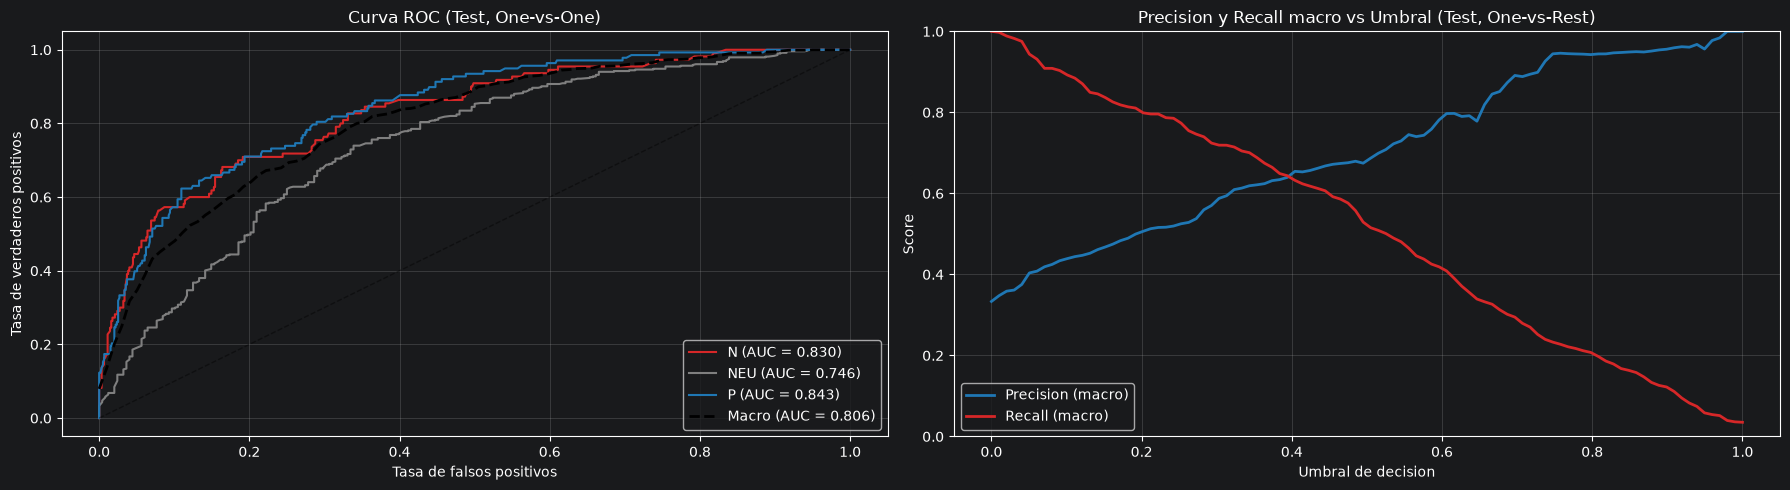

In [47]:
labels = ["N", "NEU", "P"]
colors = {"N": "#d62728", "NEU": "#7f7f7f", "P": "#1f77b4"}

y_test_proba = pipeline.predict_proba(X_test)
y_test_bin = label_binarize(y_test, classes=labels)

fig, axes = plt.subplots(1, 2, figsize=(18, 5))

# ROC y PR por clase (One-vs-Rest)
fpr_dict, tpr_dict, roc_aucs = {}, {}, {}
prec_dict, rec_dict = {}, {}

for i, label in enumerate(labels):
    fpr_dict[label], tpr_dict[label], _ = roc_curve(y_test_bin[:, i], y_test_proba[:, i])
    roc_aucs[label] = auc(fpr_dict[label], tpr_dict[label])
    prec_dict[label], rec_dict[label], _ = precision_recall_curve(y_test_bin[:, i], y_test_proba[:, i])

# Promedio macro de las curvas (interpolacion sobre la malla comun)
mean_fpr = np.linspace(0, 1, 100)
mean_tpr = np.mean([np.interp(mean_fpr, fpr_dict[l], tpr_dict[l]) for l in labels], axis=0)
macro_auc = auc(mean_fpr, mean_tpr)

# 1) Curva ROC multiclase (OvR) + macro
for label in labels:
    axes[0].plot(fpr_dict[label], tpr_dict[label], color=colors[label], lw=1.5,
                 label=f"{label} (AUC = {roc_aucs[label]:.3f})")
axes[0].plot(mean_fpr, mean_tpr, color="black", lw=2, linestyle="--",
             label=f"Macro (AUC = {macro_auc:.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1, alpha=0.4)
axes[0].set_title("Curva ROC (Test, One-vs-One)")
axes[0].set_xlabel("Tasa de falsos positivos")
axes[0].set_ylabel("Tasa de verdaderos positivos")
axes[0].legend(loc="lower right")
axes[0].grid(alpha=0.3)

# 2) Precision y Recall macro en funcion del umbral
thr_grid = np.linspace(0, 1, 100)
prec_interp, rec_interp = [], []
for label in labels:
    prec, rec, thr = precision_recall_curve(y_test_bin[:, labels.index(label)],
                                             y_test_proba[:, labels.index(label)])
    prec_interp.append(np.interp(thr_grid, thr, prec[:-1]))
    rec_interp.append(np.interp(thr_grid, thr, rec[:-1]))

macro_prec = np.mean(prec_interp, axis=0)
macro_rec = np.mean(rec_interp, axis=0)

axes[1].plot(thr_grid, macro_prec, color="#1f77b4", lw=2, label="Precision (macro)")
axes[1].plot(thr_grid, macro_rec, color="#d62728", lw=2, label="Recall (macro)")
axes[1].set_title("Precision y Recall macro vs Umbral (Test, One-vs-Rest)")
axes[1].set_xlabel("Umbral de decision")
axes[1].set_ylabel("Score")
axes[1].set_ylim(0, 1)
axes[1].legend(loc="best")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [49]:
# --- Prueba manual del pipeline ---
# Escribí acá el tweet a evaluar. El resto de los valores numéricos van en 0.
tweet = "Es una cagada! Nos va a sacar el trabajo y encima lo hace mal"

# Una fila con el texto y los 9 features numéricos en 0
# Nota: como los numéricos pasan por StandardScaler, un 0 significa "valor promedio del train"
entrada = pd.DataFrame([{"text": tweet, **{col: 0 for col in number_columns}}])

pred = pipeline.predict(entrada)[0]
probas = pipeline.predict_proba(entrada)[0]

print(f"Tweet:  {tweet}")
print(f"Predicción: {pred}")

print("Probabilidades por clase:")
print(pd.Series(probas, index=pipeline.classes_).round(4))

Tweet:  Es una cagada! Nos va a sacar el trabajo y encima lo hace mal
Predicción: N
Probabilidades por clase:
N      0.5318
NEU    0.4332
P      0.0349
dtype: float64
